<a href="https://colab.research.google.com/github/christinafan-cell/MSSP607/blob/main/Assignment2_Christina_Fan.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Adventure Works Internet Sales Analysis
Christina Fan | Case Study Report Assignment 2

### 1. Import libraries and upload the file

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from google.colab import files
uploaded = files.upload()
file_name = next(iter(uploaded))
df = pd.read_csv(file_name, encoding='latin1', low_memory=False)
df.head()

Saving InternetSales (1).csv to InternetSales (1).csv


,ID,CustomerKey,GeographyKey,City,CountryRegionCode,EnglishCountryRegionName,CustomerAlternateKey,Title,FirstName,MiddleName,...,ProductStandardCost,TotalProductCost,SalesAmount,TaxAmt,Freight,CarrierTrackingNumber,CustomerPONumber,OrderDate,DueDate,ShipDate
0,0,11000,26,Rockhampton,AU,Australia,AW00011000,NaN,Jon,V,...,1912.1544,1912.1544,3399.99,271.9992,84.9998,NaN,NaN,1/19/2011,1/31/2011,1/26/2011
1,1,11000,26,Rockhampton,AU,Australia,AW00011000,NaN,Jon,V,...,1265.6195,1265.6195,2319.99,185.5992,57.9998,NaN,NaN,1/18/2013,1/30/2013,1/25/2013
2,2,11000,26,Rockhampton,AU,Australia,AW00011000,NaN,Jon,V,...,8.2205,8.2205,21.98,1.7584,0.5495,NaN,NaN,1/18/2013,1/30/2013,1/25/2013
3,3,11000,26,Rockhampton,AU,Australia,AW00011000,NaN,Jon,V,...,1481.9379,1481.9379,2384.07,190.7256,59.6018,NaN,NaN,5/3/2013,5/15/2013,5/10/2013
4,4,11000,26,Rockhampton,AU,Australia,AW00011000,NaN,Jon,V,...,10.8423,10.8423,28.99,2.3192,0.7248,NaN,NaN,5/3/2013,5/15/2013,5/10/2013


### 2. Check the data and create the year

In [2]:
df['OrderDate'] = pd.to_datetime(df['OrderDate'])
df['Year'] = df['OrderDate'].dt.year
columns = ['CustomerKey', 'EnglishCountryRegionName', 'Gender', 'YearlyIncome',
           'HouseOwnerFlag', 'EnglishProductName', 'OrderQuantity', 'UnitPrice', 'SalesAmount']
print('Rows and original columns:', len(df), len(df.columns) - 1)
print('Missing values:', df[columns].isna().sum())
print('Repeated order lines:', df.duplicated(['SalesOrderNumber', 'SalesOrderLineNumber']).sum())
coverage = df.groupby('Year')['OrderDate'].agg(['min', 'max', 'nunique'])
display(coverage)

Rows and original columns: 60398 60
Missing values: CustomerKey                 0
EnglishCountryRegionName    0
Gender                      0
YearlyIncome                0
HouseOwnerFlag              0
EnglishProductName          0
OrderQuantity               0
UnitPrice                   0
SalesAmount                 0
dtype: int64
Repeated order lines: 0


,min,max,nunique
Year,,,
2010,2010-12-29,2010-12-31,3
2011,2011-01-01,2011-12-31,362
2012,2012-01-01,2012-12-31,366
2013,2013-01-01,2013-12-31,365
2014,2014-01-01,2014-01-28,28


### 3. Create product categories

In [3]:
df['Category'] = 'Accessories'
df.loc[df['EnglishProductName'].str.contains('Cap|Jersey|Gloves|Shorts|Socks|Vest'), 'Category'] = 'Clothing'
df.loc[df['EnglishProductName'].str.startswith(('Road-', 'Mountain-', 'Touring-')), 'Category'] = 'Bikes'
display(df[['EnglishProductName', 'Category']].drop_duplicates().sort_values(['Category', 'EnglishProductName']))

,EnglishProductName,Category
95,All-Purpose Bike Stand,Accessories
158,Bike Wash - Dissolver,Accessories
2,Fender Set - Mountain,Accessories
40,HL Mountain Tire,Accessories
572,HL Road Tire,Accessories
...,...,...
7,"Short-Sleeve Classic Jersey, S",Clothing
12,"Short-Sleeve Classic Jersey, XL",Clothing
1473,"Women's Mountain Shorts, L",Clothing
137,"Women's Mountain Shorts, M",Clothing


### 4. Summarize sales by year and country region


,SalesAmount
Year,
2010,43421.04
2011,7075525.93
2012,5842485.20
2013,16351550.34
2014,45694.72


Year,2010,2011,2012,2013,2014
EnglishCountryRegionName,,,,,
Australia,20909.78,2563732.25,2128407.46,4339443.38,8507.72
Canada,3578.27,571571.80,307604.52,1085632.65,9457.62
France,3399.99,410845.33,648065.54,1578511.80,3195.06
Germany,0.00,520500.16,608657.98,1761876.36,3277.83
United Kingdom,699.10,550591.22,712700.96,2124007.29,3713.64
United States,14833.90,2458285.17,1437048.73,5462078.86,17542.85


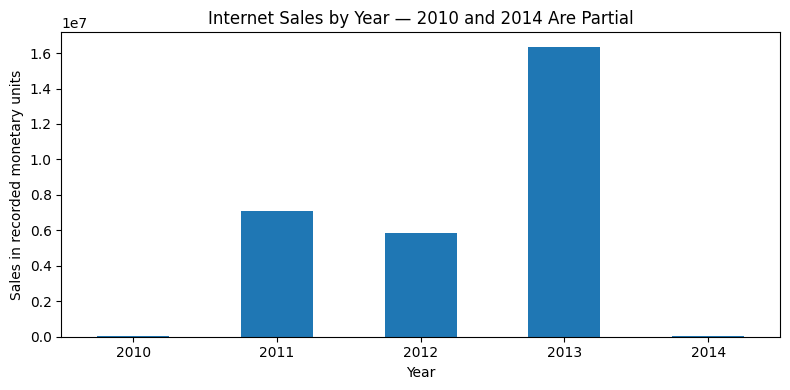

In [4]:
yearly_sales = df.groupby('Year')['SalesAmount'].sum()
country_sales = df.pivot_table(index='EnglishCountryRegionName', columns='Year',
                              values='SalesAmount', aggfunc='sum', fill_value=0)
display(yearly_sales.round(2))
display(country_sales.round(2))
yearly_sales.plot(kind='bar', figsize=(8, 4), rot=0)
plt.title('Internet Sales by Year — 2010 and 2014 Are Partial')
plt.xlabel('Year')
plt.ylabel('Sales in recorded monetary units')
plt.tight_layout()
plt.show()

### 5. Summarize sales by year and product category

Category,Accessories,Bikes,Clothing
Year,,,
2010,0.00,43421.04,0.00
2011,0.00,7075525.93,0.00
2012,2147.08,5839695.33,642.79
2013,668241.53,15359502.36,323806.45
2014,30371.35,0.00,15323.37


,Revenue,Units,RevenueSharePct
Category,,,
Accessories,700759.96,36092,2.39
Bikes,28318144.65,15205,96.46
Clothing,339772.61,9101,1.16


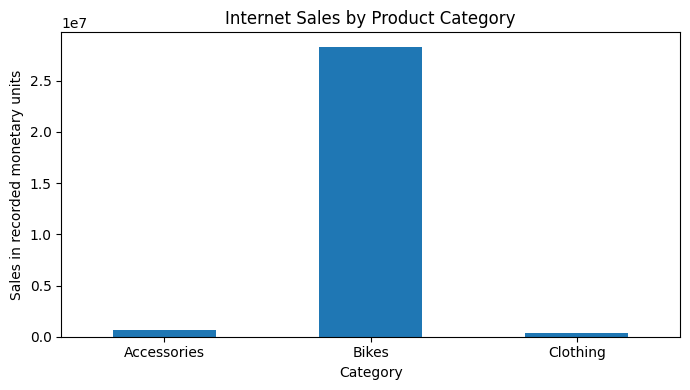

In [5]:
category_year = df.pivot_table(index='Year', columns='Category',
                              values='SalesAmount', aggfunc='sum', fill_value=0)
category_summary = df.groupby('Category').agg(Revenue=('SalesAmount', 'sum'),
                                            Units=('OrderQuantity', 'sum'))
category_summary['RevenueSharePct'] = category_summary['Revenue'] / category_summary['Revenue'].sum() * 100
display(category_year.round(2))
display(category_summary.round(2))
category_summary['Revenue'].plot(kind='bar', figsize=(7, 4), rot=0)
plt.title('Internet Sales by Product Category')
plt.ylabel('Sales in recorded monetary units')
plt.tight_layout()
plt.show()

### 6. Create one record per customer

In [6]:
attributes = ['EnglishCountryRegionName', 'Gender', 'YearlyIncome', 'HouseOwnerFlag']
print('Maximum distinct values per customer:')
print(df.groupby('CustomerKey')[attributes].nunique().max())
customers = df.drop_duplicates('CustomerKey')
print('Unique purchasing customers:', len(customers))

Maximum distinct values per customer:
EnglishCountryRegionName    1
Gender                      1
YearlyIncome                1
HouseOwnerFlag              1
dtype: int64
Unique purchasing customers: 18484


### 7. Summarize yearly income by country and gender

In [7]:
income_country = customers.groupby('EnglishCountryRegionName')['YearlyIncome'].agg(['count', 'mean', 'min', 'max', 'std'])
income_gender = customers.groupby(['EnglishCountryRegionName', 'Gender'])['YearlyIncome'].agg(['count', 'mean', 'min', 'max', 'std'])
display(income_country.round(2))
display(income_gender.round(2))

,count,mean,min,max,std
EnglishCountryRegionName,,,,,
Australia,3591,64338.62,10000,170000,31830.00
Canada,1571,57167.41,10000,170000,20251.52
France,1810,35762.43,10000,110000,27277.40
Germany,1780,42943.82,10000,130000,35493.58
United Kingdom,1913,52169.37,10000,170000,48431.99
United States,7819,63616.83,10000,170000,25706.48


count      mean    min     max       std
EnglishCountryRegionName Gender                                          
Australia                F        1777  65284.19  10000  160000  31164.36
                         M        1814  63412.35  10000  170000  32450.71
Canada                   F         767  56505.87  10000  170000  19181.55
                         M         804  57798.51  10000  170000  21214.77
France                   F         893  35341.55  10000  110000  26915.85
                         M         917  36172.30  10000  110000  27633.45
Germany                  F         874  43810.07  10000  130000  35715.76
                         M         906  42108.17  10000  130000  35277.49
United Kingdom           F         934  52184.15  10000  170000  48288.44
                         M         979  52155.26  10000  170000  48593.22
United States            F        3888  63276.75  10000  170000  25166.56
                         M        3931  63953.19  10000  170000  26228.43

### 8. Summarize gender by country

In [8]:
gender_counts = pd.crosstab(customers['EnglishCountryRegionName'], customers['Gender'])
gender_percent = gender_counts.div(gender_counts.sum(axis=1), axis=0) * 100
display(gender_counts)
display(gender_percent.round(2))

Gender,F,M
EnglishCountryRegionName,,
Australia,1777,1814
Canada,767,804
France,893,917
Germany,874,906
United Kingdom,934,979
United States,3888,3931


Gender,F,M
EnglishCountryRegionName,,
Australia,49.48,50.52
Canada,48.82,51.18
France,49.34,50.66
Germany,49.10,50.90
United Kingdom,48.82,51.18
United States,49.73,50.27


### 9. Find the average price in the leading category


In [9]:
top_category = category_summary['Revenue'].idxmax()
top_products = df[df['Category'] == top_category]
average_price = top_products['SalesAmount'].sum() / top_products['OrderQuantity'].sum()
print('Highest-revenue category:', top_category)
print('Average realized unit price:', round(average_price, 2))

Highest-revenue category: Bikes
Average realized unit price: 1862.42


### 10. Compare sales by home ownership

In [10]:
home_sales = df.groupby('HouseOwnerFlag').agg(Revenue=('SalesAmount', 'sum'),
                                             Customers=('CustomerKey', 'nunique'),
                                             Orders=('SalesOrderNumber', 'nunique'))
home_sales['RevenuePerCustomer'] = home_sales['Revenue'] / home_sales['Customers']
home_sales['RevenuePerOrder'] = home_sales['Revenue'] / home_sales['Orders']
home_sales['OrdersPerCustomer'] = home_sales['Orders'] / home_sales['Customers']
display(home_sales.round(2))

,Revenue,Customers,Orders,RevenuePerCustomer,RevenuePerOrder,OrdersPerCustomer
HouseOwnerFlag,,,,,,
0,8973327.42,5982,8601,1500.05,1043.29,1.44
1,20385349.80,12502,19058,1630.57,1069.65,1.52


### 11. Compare complete-year growth

In [11]:
display((yearly_sales.loc[2011:2013].pct_change() * 100).round(2).rename('AnnualGrowthPct'))
country_comparison = country_sales[[2012, 2013]].copy()
country_comparison['GrowthPct'] = (country_comparison[2013] / country_comparison[2012] - 1) * 100
display(country_comparison.round(2))

,AnnualGrowthPct
Year,
2011,NaN
2012,-17.43
2013,179.87


Year,2012,2013,GrowthPct
EnglishCountryRegionName,,,
Australia,2128407.46,4339443.38,103.88
Canada,307604.52,1085632.65,252.93
France,648065.54,1578511.80,143.57
Germany,608657.98,1761876.36,189.47
United Kingdom,712700.96,2124007.29,198.02
United States,1437048.73,5462078.86,280.09
